# 5. Light-Sheet smFRET Camera Simulation

This notebook simulates **camera frames of fluorescence emission** from freely diffusing particles, as observed with a light-sheet microscope. It takes the particle-diffusion machinery of `1_Trajectory_Simulation.ipynb` and replaces the confocal PSF + TCSPC-timestamp detection with a **light-sheet PSF + camera**.

The light-sheet PSF is computed with the [`psfmodels`](https://github.com/scottptt/psfmodels) module and wrapped in the class `LightSheetPSF` (`lightsheet_psf.py`), which implements the pybromo PSF interface (`eval`, `eval_xz`, `hash`, `to_hdf5`).

The physical model is deliberately simple:

1. **Excitation**: a Gaussian light sheet, thin in $z$ and uniform in $x/y$. For a sheet formed by a low-NA Gaussian beam, the 1/e² intensity waist is $w_0 = \lambda_{ex} / (\pi\,\mathrm{NA}_{sheet})$, so the excitation intensity at particle height $z$ is

$$I_{exc}(z) = \exp\left(-2\,(z/w_0)^2\right).$$

2. **Detection**: the vectorial widefield PSF of the detection objective (Gibson–Lanni model, `psfmodels.make_psf`), evaluated on a $z$ stack so that particles away from the focal plane form **broadened, dimmer** camera spots, with the photon number conserved per $z$ plane.

3. **Effective PSF**: the product $I_{exc}(z) \cdot PSF_{det}(x, y, z)$, precomputed on a 3D grid and linearly interpolated (`eval`).

4. **Camera frames**: for each 50 ms frame, the expected photon counts of each particle (modulated by the sheet profile at its $z$ position) are binned on the camera pixel grid per $z$ plane, convolved with the sum-normalized detection kernel at that defocus, and Poisson-sampled into integer pixel counts.

In [1]:
%matplotlib inline
import numpy as np
import tables
import matplotlib.pyplot as plt
import pybromo as pbm
import psfmodels
from lightsheet_psf import LightSheetPSF

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

/workspace/github__Tomkaehst__PyBroMo/pybromo/psflib.py:15: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Numpy version: 2.5.4
PyTables version: 3.11.1
PyBroMo version: 0+untagged.1.g5fecc87
psfmodels version: 0.3.3


## 1. The light-sheet PSF

`LightSheetPSF` parameters:

| Parameter | Value | Meaning |
|---|---|---|
| `dxy` | 0.2 µm | lateral grid step = camera pixel size (sample space) |
| `nx` | 51 | lateral grid size |
| `dz`, `nz_half` | 0.25 µm, 24 | z grid spanning ±6 µm around focus |
| `det_NA` | 0.8 | detection objective NA |
| `em_wvl` | 0.58 µm | emission wavelength |
| `ex_wvl`, `sheet_NA` | 0.488 µm, 0.08 | light-sheet excitation |

In [2]:
ls_psf = LightSheetPSF(dxy=0.2, nx=51, dz=0.25, nz_half=24,
                        det_NA=0.8, em_wvl=0.58,
                        ex_wvl=0.488, sheet_NA=0.08)
print(ls_psf)
print('Sheet 1/e^2 waist w0: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])

LightSheetPSF(dxy=0.2um, nx=51, dz=0.25um, nz_half=24, det_NA=0.8, em_wvl=0.58um, ex_wvl=0.488um, sheet_NA=0.08)
Sheet 1/e^2 waist w0: 1.94 um
PSF volume: (49, 51, 51)
PSF hash: 2e7ea8185848


## 2. Validation of the physical model

Before simulating camera data, the PSF is checked against the analytical expectations:

- **Lateral width**: the diffraction-limited detection PSF has an Airy-profile FWHM $\approx 0.51\,\lambda/\mathrm{NA}$ (fine 0.05 µm grid to avoid pixel-size bias)
- **Axial extent**: the effective light-sheet PSF must be confined in $z$ by the sheet, not by the detection depth of field
- **Photon conservation**: the sum-normalized detection kernels must conserve photon counts at every defocus
- **Defocus broadening**: the camera spot of a particle must broaden (and dim) away from focus

In [3]:
# --- Validation on a fine lateral grid (0.05 um) to measure true widths ---
ls_fine = LightSheetPSF(dxy=0.05, nx=101, dz=0.25, nz_half=24)

def fwhm(profile, step):
    prof = profile / profile.max()
    idx = np.where(prof >= 0.5)[0]
    return (idx[-1] - idx[0] + 1) * step

# Lateral: in-focus detection PSF vs Airy FWHM 0.51*lam/NA
k0 = ls_fine.detection_kernel(0.0)
lat_fwhm = fwhm(k0[k0.shape[0]//2], ls_fine.dxy)
airy_fwhm = 0.51 * ls_fine.em_wvl / ls_fine.det_NA
print(f"In-focus detection FWHM: {lat_fwhm:.3f} um   (Airy theory: {airy_fwhm:.3f} um)")

# Axial: effective PSF is confined by BOTH the sheet Gaussian and the
# detection depth of field; it must be narrower than either alone
zprof = ls_fine.psf_volume[:, ls_fine.nx//2, ls_fine.nx//2]
ax_fwhm = fwhm(zprof, ls_fine.dz)
det_z = ls_fine.detection_psf[:, ls_fine.nx//2, ls_fine.nx//2]
det_ax_fwhm = fwhm(det_z, ls_fine.dz)
sheet_fwhm = 2 * np.sqrt(2*np.log(2)) * ls_fine.sheet_waist
print(f"Effective axial FWHM:     {ax_fwhm:.3f} um   (detection-only: {det_ax_fwhm:.3f} um, sheet-only: {sheet_fwhm:.3f} um)")
assert ax_fwhm < det_ax_fwhm and ax_fwhm < sheet_fwhm, "effective PSF must be narrower than both factors"
print("  -> narrower than both the detection DOF and the sheet alone, as expected")

# Photon conservation of the rendering: single particle at fixed positions
em_rate, t_step, n = 50e3, 1e-3, 200
print("\nPhoton conservation (particle at x=y=0, fixed z, 200 ms exposure):")
for z_fix in [0.0, 1e-6, 2e-6, 4e-6]:
    x = np.zeros((1, n)); y = np.zeros((1, n)); z = np.full((1, n), z_fix)
    img = ls_psf.render_frame_expected(x, y, z, em_rate=em_rate, t_step=t_step)
    expected = em_rate * t_step * n * ls_psf.excitation_weights(np.array([z_fix]))[0]
    print(f"  z = {z_fix*1e6:+.0f} um: expected {expected:8.1f} photons, rendered {img.sum():8.1f}")

# Defocus broadening of the camera spot
print("\nDefocus broadening (camera spot FWHM at 0.2 um pixels):")
for z_fix in [0.0, 1e-6, 2e-6]:
    z = np.full((1, n), z_fix)
    img = ls_psf.render_frame_expected(x, y, z, em_rate=em_rate, t_step=t_step)
    row = img[img.shape[0]//2]
    print(f"  z = {z_fix*1e6:+.0f} um: spot FWHM = {fwhm(row, 0.2):.2f} um, peak = {img.max():.0f} counts/px")

In-focus detection FWHM: 0.350 um   (Airy theory: 0.370 um)
Effective axial FWHM:     1.250 um   (detection-only: 1.750 um, sheet-only: 4.572 um)
  -> narrower than both the detection DOF and the sheet alone, as expected

Photon conservation (particle at x=y=0, fixed z, 200 ms exposure):
  z = +0 um: expected  10000.0 photons, rendered  10000.0
  z = +1 um: expected   5883.2 photons, rendered   5883.2
  z = +2 um: expected   1198.0 photons, rendered   1198.0
  z = +4 um: expected      2.1 photons, rendered      2.1

Defocus broadening (camera spot FWHM at 0.2 um pixels):
  z = +0 um: spot FWHM = 0.60 um, peak = 1939 counts/px
  z = +1 um: spot FWHM = 0.60 um, peak = 546 counts/px
  z = +2 um: spot FWHM = 1.80 um, peak = 16 counts/px


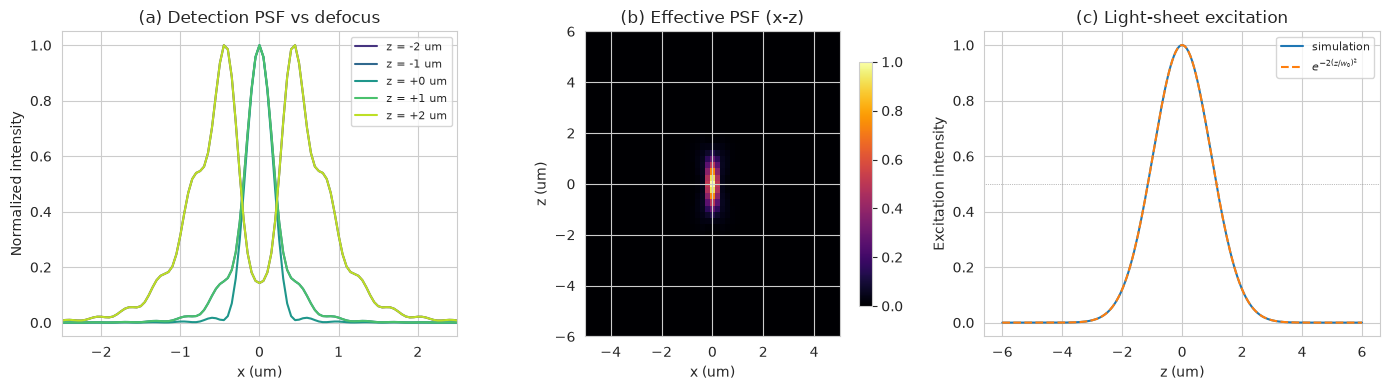

In [4]:
import os
os.makedirs('lightsheet_sim_plots', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# (a) Detection PSF at several defocus planes (fine grid)
z_show = [-2, -1, 0, 1, 2]
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(z_show)))
c = ls_fine.nx // 2
r_um = (np.arange(ls_fine.nx) - c) * ls_fine.dxy
for z_um, col in zip(z_show, colors):
    k = ls_fine.detection_kernel(z_um * 1e-6)
    axes[0].plot(r_um, k[c] / k[c].max(), color=col, label=f"z = {z_um:+d} um")
axes[0].set_xlim(-2.5, 2.5)
axes[0].set_xlabel("x (um)"); axes[0].set_ylabel("Normalized intensity")
axes[0].set_title("(a) Detection PSF vs defocus"); axes[0].legend(fontsize=8)

# (b) Effective light-sheet PSF, x-z slice
xz = ls_psf.eval_xz(np.meshgrid(np.linspace(-5e-6, 5e-6, 51),
                                np.linspace(-6e-6, 6e-6, 49))[0],
                    np.meshgrid(np.linspace(-5e-6, 5e-6, 51),
                                np.linspace(-6e-6, 6e-6, 49))[1])
im = axes[1].imshow(xz, extent=[-5, 5, -6, 6], origin='lower', cmap='inferno')
axes[1].set_title("(b) Effective PSF (x-z)")
axes[1].set_xlabel("x (um)"); axes[1].set_ylabel("z (um)")
plt.colorbar(im, ax=axes[1], shrink=0.8)

# (c) Light-sheet excitation profile vs Gaussian theory
z_um = np.linspace(-6, 6, 200)
axes[2].plot(z_um, ls_psf.excitation_weights(z_um * 1e-6), label="simulation")
axes[2].plot(z_um, np.exp(-2*(z_um/ls_psf.sheet_waist)**2), '--', label=r"$e^{-2(z/w_0)^2}$")
axes[2].axhline(0.5, color='gray', lw=0.5, ls=':')
axes[2].set_xlabel("z (um)"); axes[2].set_ylabel("Excitation intensity")
axes[2].set_title("(c) Light-sheet excitation"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig1_psf_validation.png', dpi=150, bbox_inches='tight');

## 3. Particle diffusion simulation (pybromo, camera parameters)

Camera-system simulation parameters:

| Parameter | Value |
|---|---|
| Simulation duration | 100 s |
| Simulation time step | 1 ms |
| Camera frame integration time | 50 ms (50 steps/frame) |
| Diffusion coefficient | 10 µm²/s |
| Particles | 15 |
| Simulation box | 25.6 × 25.6 × 16 µm³ (= 128 × 128 px at 0.2 µm/px) |

In [5]:
rs = np.random.RandomState()
print('Initial random state:', pbm.hashfunc(rs.get_state()))

# Camera system parameters
t_step = 1e-3        # simulation step: 1 ms
t_max = 100          # total simulated time: 100 s
frame_steps = 50     # camera frame integration: 50 steps = 50 ms
frame_time = frame_steps * t_step
pixel_size = 0.2e-6  # camera pixel size in sample space (m)
roi = 128            # camera ROI in pixels

n_frames = int(t_max / frame_time)
print(f'Number of camera frames: {n_frames}')

box = pbm.Box(x1=-roi/2*pixel_size, x2=roi/2*pixel_size,
              y1=-roi/2*pixel_size, y2=roi/2*pixel_size,
              z1=-8e-6, z2=8e-6)

Du = 10.0            # um^2 / s
D1 = Du*(1e-6)**2    # m^2 / s
n_particles = 15
P = pbm.Particles.from_specs(num_particles=(n_particles,), D=(D1,), box=box, rs=rs)

S = pbm.ParticlesSimulation(t_step=t_step, t_max=t_max, particles=P, box=box, psf=ls_psf)
print(S)
S.print_sizes()

Initial random state: 65503c3e2233600ead1e00264645e09132acb03a
Number of camera frames: 2000
Box: X 25.6um, Y 25.6um, Z 16.0um
#Particles: 15 D: 1e-11, 2.4 pM, t_step 1000.0us, t_max 100.0s ID_EID 0 0
  Number of particles: 15
  Number of time steps: 100000
  Emission array - 1 particle (float32): 0.4 MB
  Emission array (float32): 5.7 MB
  Position array (float32): 17.2 MB 


In [6]:
S.simulate_diffusion(
    total_emission=False,
    save_pos=True,
    verbose=True,
    rs=rs,
    chunksize=2**20,
    chunkslice='times'
)

- Start trajectories simulation - Tue Oct 27 22:06:31 2026


[PID 1779] Diffusion time: 1048s


- End trajectories simulation - Tue Oct 27 22:06:31 2026


## 4. Camera frames from the PSF convolution

For each 50 ms frame:

1. **Excitation weighting**: each particle's emission is modulated by the light-sheet profile at its $z$ position — particles outside the sheet go dark
2. **Pixel binning per z plane**: expected photon counts are binned on the 128 × 128 camera grid, grouped by $z$ plane
3. **PSF convolution**: each $z$ slice is convolved with the sum-normalized detection kernel at that defocus — in-focus particles form diffraction-limited spots, defocused ones broad, dim spots
4. **Shot noise**: Poisson sampling yields integer photon counts per pixel (uint16)

Emission rate: 50 kcps per particle at the sheet center; camera background: 10 cps/pixel.

In [7]:
positions = S.position[:]   # (num_particles, 3, n_samples)
print('Positions array:', positions.shape)
print('Samples:', positions.shape[-1], '-> frames:', positions.shape[-1] // frame_steps)

em_rate = 50e3        # photons/s per particle at the sheet center
background_rate = 10  # photons/s/pixel

frames = ls_psf.render_camera_frames(
    positions,
    t_step=t_step,
    frame_steps=frame_steps,
    em_rate=em_rate,
    roi=roi,
    pixel_size_m=pixel_size,
    background_rate=background_rate,
    rs=rs)
print('Camera frames:', frames.shape, frames.dtype)
print('Photons per frame (mean):', frames.sum(axis=(1, 2)).mean().round(1))

Positions array: (15, 3, 100000)
Samples: 100000 -> frames: 2000


Camera frames: (2000, 128, 128) uint16
Photons per frame (mean): 13877.1


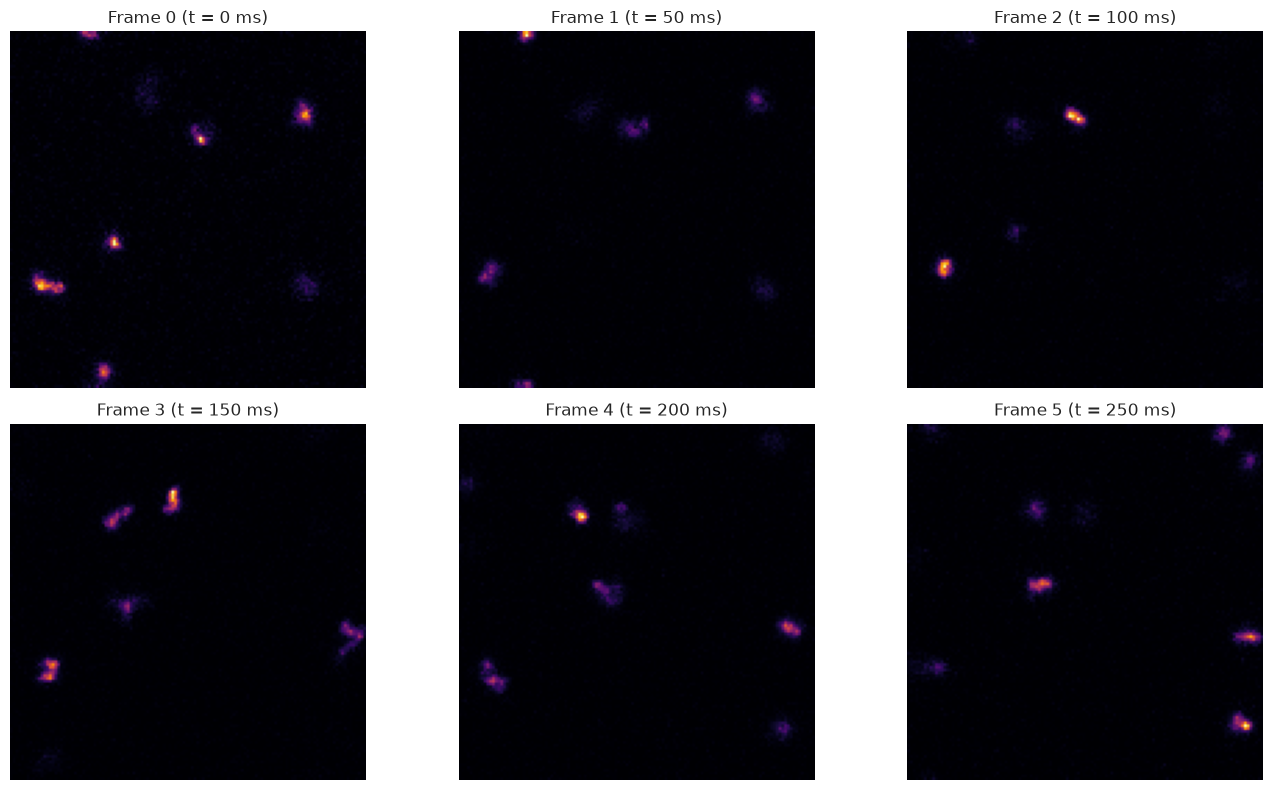

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i], cmap='inferno')
    ax.set_title(f'Frame {i} (t = {i*frame_time*1e3:.0f} ms)')
    ax.set_axis_off()
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig2_camera_frames.png', dpi=150, bbox_inches='tight');

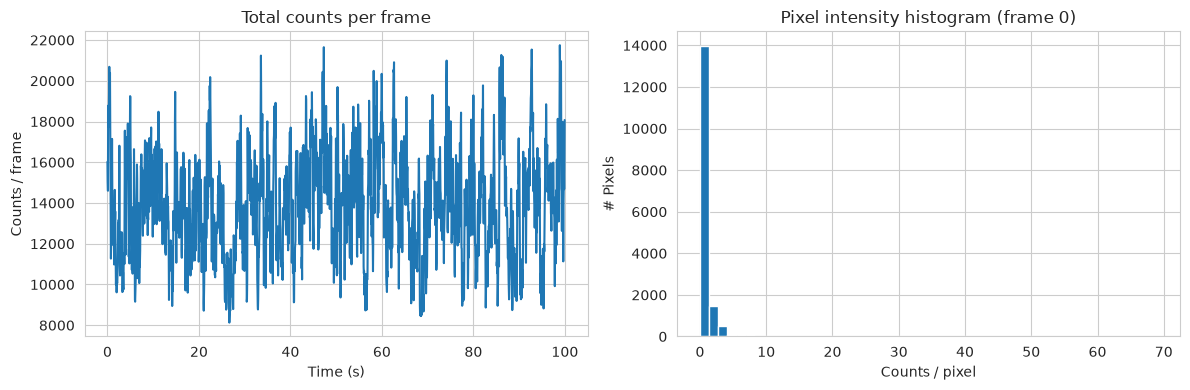

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_frames = np.arange(frames.shape[0]) * frame_time
axes[0].plot(t_frames, frames.sum(axis=(1, 2)))
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('Counts / frame')
axes[0].set_title('Total counts per frame')

f_max = frames[0].max()
axes[1].hist(frames[0].ravel(), bins=50, range=(0, f_max))
axes[1].set_xlabel('Counts / pixel'); axes[1].set_ylabel('# Pixels')
axes[1].set_title('Pixel intensity histogram (frame 0)')
plt.tight_layout()
plt.savefig('lightsheet_sim_plots/fig3_intensity_stats.png', dpi=150, bbox_inches='tight');

## 5. Save the camera frames

The frame stack is saved as HDF5 with the acquisition parameters as attributes. The pybromo trajectory file already contains the light-sheet PSF (via `LightSheetPSF.to_hdf5`), so the simulation is fully traceable.

In [10]:
sim_name = S.compact_name()
S.store.close()

filename = f'lightsheet_camera_{sim_name}.hdf5'
with tables.open_file(filename, 'w') as f:
    f.create_array('/', 'frames', obj=frames,
                   title='Simulated light-sheet camera frames (uint16)')
    for attr, value in [('frame_time', frame_time),
                        ('t_step', t_step),
                        ('pixel_size_m', pixel_size),
                        ('em_rate', em_rate),
                        ('background_rate', background_rate),
                        ('psf_hash', ls_psf.hash())]:
        f.set_node_attr(f.root, attr, value)
print('Saved:', filename)

Saved: lightsheet_camera_6c1591_P15_D1e-11_2pM_step1000.0us_t_max100.0s_ID0-0.hdf5


## Summary

- `lightsheet_psf.py` provides `LightSheetPSF`, a pybromo-compatible light-sheet PSF: a Gaussian excitation sheet ($w_0 = \lambda_{ex}/(\pi\,\mathrm{NA}_{sheet})$) multiplied by the `psfmodels` vectorial widefield detection PSF evaluated on a z stack.
- The pybromo particle simulation runs with camera parameters: **100 s duration, 1 ms step, 50 ms frame integration** (2000 frames of 128 × 128 pixels).
- `LightSheetPSF.render_camera_frames` bins the particle emission on the camera grid per z plane, convolves with the defocus-dependent detection kernel (photon-conserving), and Poisson-samples the result into uint16 camera frames.
- Validation: in-focus detection FWHM matches the Airy limit, the effective PSF is axially confined by the sheet Gaussian, photon counts are conserved at every defocus, and camera spots broaden away from focus.